In [1]:
# value_counts
# sort_values
# rank
# sort index
# set index
# rename index -> rename
# reset index
# unique & nunique
# isnull/notnull/hasnans
# dropna
# fillna
# drop_duplicates
# drop
# apply
# isin
# corr
# nlargest -> nsmallest
# insert
# copy

In [2]:
import numpy as np
import pandas as pd

In [3]:
# value_counts
data = pd.DataFrame(
    [[100 , 80 , 20],
    [90 , 70 , 20],
    [110 , 50 , 30],
    [110 , 50 , 30]] ,
    columns = ['marks' , 'iq' , 'package']
)

In [4]:
data

,marks,iq,package
0,100,80,20
1,90,70,20
2,110,50,30
3,110,50,30


In [5]:
data.value_counts()

marks  iq  package
110    50  30         2
100    80  20         1
90     70  20         1
Name: count, dtype: int64

In [6]:
ipl = pd.read_csv('ipl-matches.csv')

In [7]:
ipl.sample(5)

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
778,419162,Mumbai,2010-04-21,2009/10,Semi Final,Royal Challengers Bangalore,Mumbai Indians,Dr DY Patil Sports Academy,Mumbai Indians,bat,N,Mumbai Indians,Runs,35.0,NaN,KA Pollard,"['JH Kallis', 'R Dravid', 'KP Pietersen', 'RV ...","['S Dhawan', 'SR Tendulkar', 'AM Nayar', 'AT R...",BR Doctrove,RB Tiffin
436,829817,Mumbai,2015-05-19,2015,Qualifier 1,Chennai Super Kings,Mumbai Indians,Wankhede Stadium,Mumbai Indians,bat,N,Mumbai Indians,Runs,25.0,NaN,KA Pollard,"['DR Smith', 'MEK Hussey', 'F du Plessis', 'SK...","['LMP Simmons', 'PA Patel', 'RG Sharma', 'KA P...",HDPK Dharmasena,RK Illingworth
191,1216534,NaN,2020-09-21,2020/21,3,Royal Challengers Bangalore,Sunrisers Hyderabad,Dubai International Cricket Stadium,Sunrisers Hyderabad,field,N,Royal Challengers Bangalore,Runs,10.0,NaN,YS Chahal,"['D Padikkal', 'AJ Finch', 'V Kohli', 'AB de V...","['DA Warner', 'JM Bairstow', 'MK Pandey', 'PK ...",AY Dandekar,Nitin Menon
882,392191,Durban,2009-04-24,2009,11,Royal Challengers Bangalore,Kings XI Punjab,Kingsmead,Royal Challengers Bangalore,bat,N,Kings XI Punjab,Wickets,7.0,NaN,RS Bopara,"['JD Ryder', 'RV Uthappa', 'JH Kallis', 'KP Pi...","['RS Bopara', 'K Goel', 'KC Sangakkara', 'Yuvr...",BR Doctrove,TH Wijewardene
503,734029,Ranchi,2014-05-22,2014,50,Chennai Super Kings,Sunrisers Hyderabad,JSCA International Stadium Complex,Sunrisers Hyderabad,field,N,Sunrisers Hyderabad,Wickets,6.0,NaN,DA Warner,"['DR Smith', 'F du Plessis', 'SK Raina', 'DJ H...","['DA Warner', 'S Dhawan', 'NV Ojha', 'AJ Finch...",BNJ Oxenford,C Shamshuddin


In [8]:
ipl[~ipl['MatchNumber'].str.isdigit()]['Player_of_Match'].value_counts()

Player_of_Match
F du Plessis         3
KA Pollard           3
SK Raina             3
JJ Bumrah            2
SR Watson            2
AB de Villiers       2
MK Pandey            2
M Vijay              2
YK Pathan            2
A Kumble             2
HH Pandya            1
JC Buttler           1
RM Patidar           1
DA Miller            1
VR Iyer              1
SP Narine            1
RD Gaikwad           1
TA Boult             1
MP Stoinis           1
KS Williamson        1
RR Pant              1
SA Yadav             1
Rashid Khan          1
AD Russell           1
KH Pandya            1
KV Sharma            1
NM Coulter-Nile      1
Washington Sundar    1
BCJ Cutting          1
DA Warner            1
MC Henriques         1
RG Sharma            1
A Nehra              1
V Sehwag             1
UT Yadav             1
Harbhajan Singh      1
BJ Hodge             1
MEK Hussey           1
MS Bisla             1
MS Dhoni             1
CH Gayle             1
MM Patel             1
DE Bollinger      

<Axes: >

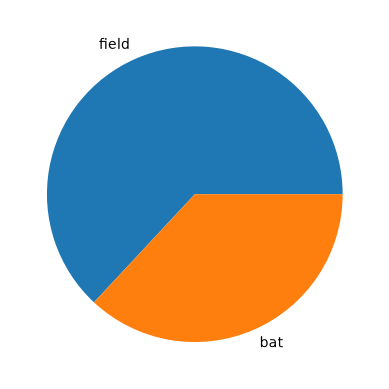

In [9]:
# toss decision plot
(ipl['TossDecision'].value_counts()).plot(kind = 'pie')

In [10]:
# how many matches each team played
(ipl['Team1'].value_counts() + ipl['Team2'].value_counts()).sort_values(ascending = False)

Team1
Mumbai Indians                 231
Royal Challengers Bangalore    226
Kolkata Knight Riders          223
Chennai Super Kings            208
Rajasthan Royals               192
Kings XI Punjab                190
Delhi Daredevils               161
Sunrisers Hyderabad            152
Deccan Chargers                 75
Delhi Capitals                  63
Pune Warriors                   46
Gujarat Lions                   30
Punjab Kings                    28
Gujarat Titans                  16
Rising Pune Supergiant          16
Lucknow Super Giants            15
Kochi Tuskers Kerala            14
Rising Pune Supergiants         14
Name: count, dtype: int64

In [11]:
# sort_values(series/DataFrame)

In [12]:
movies = pd.read_csv('movies.csv')

In [13]:
movies.sample(2)

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
722,Rush (2012 film),tt2256514,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Rush_(2012_film),Rush,Rush,0,2012,110,Crime|Thriller,3.7,793,Story of a struggling news reporter engulfed b...,Story of a struggling news reporter engulfed b...,If you stop... you die!,Emraan Hashmi|Sagarika Ghatge|Neha Dhupia|Adit...,NaN,26 October 2012 (India)
1616,Rehnaa Hai Terre Dil Mein,tt0299108,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Rehnaa_Hai_Terre...,Rehnaa Hai Terre Dil Mein,Rehnaa Hai Terre Dil Mein,0,2001,160,Musical|Romance,7.5,6232,Madhav (Maddy) has love at first site with Ree...,A young girl is torn between an obsessive love...,NaN,Madhavan|Saif Ali Khan|Dia Mirza|Vrajesh Hirje...,2 wins & 4 nominations,19 October 2001 (India)


In [14]:
movies.sort_values('title_x', ascending = False)

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
1623,Zubeidaa,tt0255713,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zubeidaa,Zubeidaa,Zubeidaa,0,2001,153,Biography|Drama|History,6.2,1384,The film begins with Riyaz (Rajat Kapoor) Zub...,Zubeidaa an aspiring Muslim actress marries ...,The Story of a Princess,Karisma Kapoor|Rekha|Manoj Bajpayee|Rajit Kapo...,3 wins & 13 nominations,19 January 2001 (India)
939,Zor Lagaa Ke...Haiya!,tt1479857,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zor_Lagaa_Ke...H...,Zor Lagaa Ke... Haiya!,Zor Lagaa Ke... Haiya!,0,2009,\N,Comedy|Drama|Family,6.4,46,A tree narrates the story of four Mumbai-based...,Children build a tree-house to spy on a beggar...,NaN,Meghan Jadhav|Mithun Chakraborty|Riya Sen|Seem...,NaN,NaN
756,Zokkomon,tt1605790,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zokkomon,Zokkomon,Zokkomon,0,2011,109,Action|Adventure,4.0,274,After the passing of his parents in an acciden...,An orphan is abused and abandoned believed to...,Betrayal. Friendship. Bravery.,Darsheel Safary|Anupam Kher|Manjari Fadnnis|Ti...,NaN,22 April 2011 (India)
670,Zindagi Tere Naam,tt2164702,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zindagi_Tere_Naam,Zindagi Tere Naam,Zindagi Tere Naam,0,2012,120,Romance,4.7,27,Mr. Singh an elderly gentleman relates to hi...,Mr. Singh an elderly gentleman relates to hi...,NaN,Mithun Chakraborty|Ranjeeta Kaur|Priyanka Meht...,1 win,16 March 2012 (India)
778,Zindagi Na Milegi Dobara,tt1562872,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zindagi_Na_Mileg...,Zindagi Na Milegi Dobara,Zindagi Na Milegi Dobara,0,2011,155,Comedy|Drama,8.1,60826,Three friends decide to turn their fantasy vac...,Three friends decide to turn their fantasy vac...,NaN,Hrithik Roshan|Farhan Akhtar|Abhay Deol|Katrin...,30 wins & 22 nominations,15 July 2011 (India)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1039,1971 (2007 film),tt0983990,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/1971_(2007_film),1971,1971,0,2007,160,Action|Drama|War,7.9,1121,Based on true facts the film revolves around ...,Based on true facts the film revolves around ...,Honor the heroes.......,Manoj Bajpayee|Ravi Kishan|Deepak Dobriyal|,1 win,9 March 2007 (India)
723,1920: The Evil Returns,tt2222550,https://upload.wikimedia.org/wikipedia/en/e/e7...,https://en.wikipedia.org/wiki/1920:_The_Evil_R...,1920: Evil Returns,1920: Evil Returns,0,2012,124,Drama|Horror|Romance,4.8,1587,This story revolves around a famous poet who m...,This story revolves around a famous poet who m...,Possession is back,Vicky Ahuja|Tia Bajpai|Irma Jämhammar|Sharad K...,NaN,2 November 2012 (India)
287,1920: London,tt5638500,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/1920_London,1920 London,1920 London,0,2016,120,Horror|Mystery,4.1,1373,Shivangi (Meera Chopra) lives in London with h...,After her husband is possessed by an evil spir...,Fear strikes again,Sharman Joshi|Meera Chopra|Vishal Karwal|Suren...,NaN,6 May 2016 (USA)
1021,1920 (film),tt1301698,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/1920_(film),1920,1920,0,2008,138,Horror|Mystery|Romance,6.4,2588,A devotee of Bhagwan Shri Hanuman Arjun Singh...,After forsaking his family and religion a hus...,A Love Made in Heaven...A Revenge Born in Hell...,Rajniesh Duggall|Adah Sharma|Anjori Alagh|Raj ...,NaN,12 September 2008 (India)


In [15]:
df = pd.DataFrame({
    "Name": ["Aarav", "Diya", "Rohan", "Sneha", "Kabir", "Ishita", "Vivaan"],
    "College": ["IIT Delhi", "NIT Trichy", "BITS Pilani", "VIT Vellore",
                "IIT Bombay", "NIT Warangal", "IIIT Hyderabad"],
    "CGPA": [8.7, np.nan, 7.9, 9.1, np.nan, 8.2, 6.8],
    "Branch": ["CSE", "ECE", "Mechanical", "CSE", "ECE", np.nan, "CSE"]
})
df

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
1,Diya,NIT Trichy,NaN,ECE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
4,Kabir,IIT Bombay,NaN,ECE
5,Ishita,NIT Warangal,8.2,NaN
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [16]:
df.sort_values('Name' , ascending = False)


,Name,College,CGPA,Branch
6,Vivaan,IIIT Hyderabad,6.8,CSE
3,Sneha,VIT Vellore,9.1,CSE
2,Rohan,BITS Pilani,7.9,Mechanical
4,Kabir,IIT Bombay,NaN,ECE
5,Ishita,NIT Warangal,8.2,NaN
1,Diya,NIT Trichy,NaN,ECE
0,Aarav,IIT Delhi,8.7,CSE


In [17]:
movies.sort_values(['year_of_release', 'title_x'] , ascending = [True , False])

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
1623,Zubeidaa,tt0255713,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zubeidaa,Zubeidaa,Zubeidaa,0,2001,153,Biography|Drama|History,6.2,1384,The film begins with Riyaz (Rajat Kapoor) Zub...,Zubeidaa an aspiring Muslim actress marries ...,The Story of a Princess,Karisma Kapoor|Rekha|Manoj Bajpayee|Rajit Kapo...,3 wins & 13 nominations,19 January 2001 (India)
1625,Yeh Zindagi Ka Safar,tt0298607,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yeh_Zindagi_Ka_S...,Yeh Zindagi Ka Safar,Yeh Zindagi Ka Safar,0,2001,146,Drama,3.0,133,Hindi pop-star Sarina Devan lives a wealthy ...,A singer finds out she was adopted when the ed...,NaN,Ameesha Patel|Jimmy Sheirgill|Nafisa Ali|Gulsh...,NaN,16 November 2001 (India)
1622,Yeh Teraa Ghar Yeh Meraa Ghar,tt0298606,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yeh_Teraa_Ghar_Y...,Yeh Teraa Ghar Yeh Meraa Ghar,Yeh Teraa Ghar Yeh Meraa Ghar,0,2001,175,Comedy|Drama,5.7,704,In debt; Dayashankar Pandey is forced to go to...,In debt; Dayashankar Pandey is forced to go to...,NaN,Sunil Shetty|Mahima Chaudhry|Paresh Rawal|Saur...,1 nomination,12 October 2001 (India)
1620,Yeh Raaste Hain Pyaar Ke,tt0292740,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yeh_Raaste_Hain_...,Yeh Raaste Hain Pyaar Ke,Yeh Raaste Hain Pyaar Ke,0,2001,149,Drama|Romance,4.0,607,Two con artistes and car thieves Vicky (Ajay ...,Two con artistes and car thieves Vicky (Ajay ...,Love is a journey... not a destination,Ajay Devgn|Madhuri Dixit|Preity Zinta|Vikram G...,NaN,10 August 2001 (India)
1573,Yaadein (2001 film),tt0248617,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yaadein_(2001_film),Yaadein...,Yaadein...,0,2001,171,Drama|Musical|Romance,4.4,3034,Raj Singh Puri is best friends with L.K. Malho...,Raj Singh Puri is best friends with L.K. Malho...,memories to cherish...,Jackie Shroff|Hrithik Roshan|Kareena Kapoor|Am...,1 nomination,27 June 2001 (India)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37,Article 15 (film),tt10324144,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Article_15_(film),Article 15,Article 15,0,2019,130,Crime|Drama,8.3,13417,In the rural heartlands of India an upright p...,In the rural heartlands of India an upright p...,Farq Bahut Kar Liya| Ab Farq Laayenge.,Ayushmann Khurrana|Nassar|Manoj Pahwa|Kumud Mi...,1 win,28 June 2019 (USA)
46,Arjun Patiala,tt7881524,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Arjun_Patiala,Arjun Patiala,Arjun Patiala,0,2019,107,Action|Comedy,4.1,676,Arjun Patiala(Diljit Dosanjh)has recently been...,This spoof comedy narrates the story of a cop ...,NaN,Diljit Dosanjh|Kriti Sanon|Varun Sharma|Ronit ...,NaN,26 July 2019 (USA)
10,Amavas,tt8396186,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Amavas,Amavas,Amavas,0,2019,134,Horror|Thriller,2.8,235,Far away from the bustle of the city a young ...,The lives of a couple turn into a nightmare a...,NaN,Ali Asgar|Vivan Bhatena|Nargis Fakhri|Sachiin ...,NaN,8 February 2019 (India)
26,Albert Pinto Ko Gussa Kyun Aata Hai?,tt4355838,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Albert_Pinto_Ko_...,Albert Pinto Ko Gussa Kyun Aata Hai?,Albert Pinto Ko Gussa Kyun Aata Hai?,0,2019,100,Drama,4.8,56,Albert leaves his house one morning without te...,Albert Pinto goes missing one day and his girl...,NaN,Manav Kaul|Nandita Das|,NaN,12 April 2019 (India)


In [18]:
# rank(series)
runs = pd.read_csv('batsman_runs_ipl.csv')

In [19]:
runs.sample(4)

,batter,batsman_run
366,NM Coulter-Nile,82
440,RR Bhatkal,0
565,UT Khawaja,127
266,KMDN Kulasekara,5


In [20]:
runs['batsman_run'].rank(ascending = False)

0      166.5
1      226.0
2      535.0
3      329.0
4      402.5
       ...  
600    594.0
601    343.0
602    547.5
603     27.0
604    256.0
Name: batsman_run, Length: 605, dtype: float64

In [21]:
runs['batting_rank'] = runs['batsman_run'].rank(ascending = False )

In [22]:
runs.sort_values('batting_rank')

,batter,batsman_run,batting_rank
569,V Kohli,6634,1.0
462,S Dhawan,6244,2.0
130,DA Warner,5883,3.0
430,RG Sharma,5881,4.0
493,SK Raina,5536,5.0
...,...,...,...
570,V Pratap Singh,0,594.0
63,Abdur Razzak,0,594.0
562,U Kaul,0,594.0
65,Akash Deep,0,594.0


In [23]:
# sort_index
marks = pd.Series(
    {
        'Hindi' : 90,
        'English' : 80,
        'Maths': 100
    }
)

In [24]:
marks.sort_index()

English     80
Hindi       90
Maths      100
dtype: int64

In [25]:
movies.sort_index( ascending = False)

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
1628,Humsafar,tt2403201,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Humsafar,Humsafar,Humsafar,0,2011,35,Drama|Romance,9.0,2968,Sara and Ashar are childhood friends who share...,Ashar and Khirad are forced to get married due...,NaN,Fawad Khan|,NaN,TV Series (2011–2012)
1627,Daaka,tt10833860,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Daaka,Daaka,Daaka,0,2019,136,Action,7.4,38,Shinda tries robbing a bank so he can be wealt...,Shinda tries robbing a bank so he can be wealt...,NaN,Gippy Grewal|Zareen Khan|,NaN,1 November 2019 (USA)
1626,Sabse Bada Sukh,tt0069204,NaN,https://en.wikipedia.org/wiki/Sabse_Bada_Sukh,Sabse Bada Sukh,Sabse Bada Sukh,0,2018,\N,Comedy|Drama,6.1,13,Village born Lalloo re-locates to Bombay and ...,Village born Lalloo re-locates to Bombay and ...,NaN,Vijay Arora|Asrani|Rajni Bala|Kumud Damle|Utpa...,NaN,NaN
1625,Yeh Zindagi Ka Safar,tt0298607,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yeh_Zindagi_Ka_S...,Yeh Zindagi Ka Safar,Yeh Zindagi Ka Safar,0,2001,146,Drama,3.0,133,Hindi pop-star Sarina Devan lives a wealthy ...,A singer finds out she was adopted when the ed...,NaN,Ameesha Patel|Jimmy Sheirgill|Nafisa Ali|Gulsh...,NaN,16 November 2001 (India)
1624,Tera Mera Saath Rahen,tt0301250,https://upload.wikimedia.org/wikipedia/en/2/2b...,https://en.wikipedia.org/wiki/Tera_Mera_Saath_...,Tera Mera Saath Rahen,Tera Mera Saath Rahen,0,2001,148,Drama,4.9,278,Raj Dixit lives with his younger brother Rahu...,A man is torn between his handicapped brother ...,NaN,Ajay Devgn|Sonali Bendre|Namrata Shirodkar|Pre...,NaN,7 November 2001 (India)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,Evening Shadows,tt6028796,NaN,https://en.wikipedia.org/wiki/Evening_Shadows,Evening Shadows,Evening Shadows,0,2018,102,Drama,7.3,280,While gay rights and marriage equality has bee...,Under the 'Evening Shadows' truth often plays...,NaN,Mona Ambegaonkar|Ananth Narayan Mahadevan|Deva...,17 wins & 1 nomination,11 January 2019 (India)
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,0,2019,121,Crime|Drama,6.0,1891,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA)
2,The Accidental Prime Minister (film),tt6986710,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/The_Accidental_P...,The Accidental Prime Minister,The Accidental Prime Minister,0,2019,112,Biography|Drama,6.1,5549,Based on the memoir by Indian policy analyst S...,Explores Manmohan Singh's tenure as the Prime ...,NaN,Anupam Kher|Akshaye Khanna|Aahana Kumra|Atul S...,NaN,11 January 2019 (USA)
1,Battalion 609,tt9472208,NaN,https://en.wikipedia.org/wiki/Battalion_609,Battalion 609,Battalion 609,0,2019,131,War,4.1,73,The story revolves around a cricket match betw...,The story of Battalion 609 revolves around a c...,NaN,Vicky Ahuja|Shoaib Ibrahim|Shrikant Kamat|Elen...,NaN,11 January 2019 (India)


In [26]:
# set index
runs.sample()

,batter,batsman_run,batting_rank
144,DJ Thornely,39,358.5


In [27]:
runs.set_index('batter' , inplace = True)

In [28]:
# reset index
runs.reset_index(inplace = True)

In [29]:
runs

,batter,batsman_run,batting_rank
0,A Ashish Reddy,280,166.5
1,A Badoni,161,226.0
2,A Chandila,4,535.0
3,A Chopra,53,329.0
4,A Choudhary,25,402.5
...,...,...,...
600,Yash Dayal,0,594.0
601,Yashpal Singh,47,343.0
602,Younis Khan,3,547.5
603,Yuvraj Singh,2754,27.0


In [30]:
# rename 
movies.head()	

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
0,Uri: The Surgical Strike,tt8291224,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Uri:_The_Surgica...,Uri: The Surgical Strike,Uri: The Surgical Strike,0,2019,138,Action|Drama|War,8.4,35112,Divided over five chapters the film chronicle...,Indian army special forces execute a covert op...,NaN,Vicky Kaushal|Paresh Rawal|Mohit Raina|Yami Ga...,4 wins,11 January 2019 (USA)
1,Battalion 609,tt9472208,NaN,https://en.wikipedia.org/wiki/Battalion_609,Battalion 609,Battalion 609,0,2019,131,War,4.1,73,The story revolves around a cricket match betw...,The story of Battalion 609 revolves around a c...,NaN,Vicky Ahuja|Shoaib Ibrahim|Shrikant Kamat|Elen...,NaN,11 January 2019 (India)
2,The Accidental Prime Minister (film),tt6986710,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/The_Accidental_P...,The Accidental Prime Minister,The Accidental Prime Minister,0,2019,112,Biography|Drama,6.1,5549,Based on the memoir by Indian policy analyst S...,Explores Manmohan Singh's tenure as the Prime ...,NaN,Anupam Kher|Akshaye Khanna|Aahana Kumra|Atul S...,NaN,11 January 2019 (USA)
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,0,2019,121,Crime|Drama,6.0,1891,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA)
4,Evening Shadows,tt6028796,NaN,https://en.wikipedia.org/wiki/Evening_Shadows,Evening Shadows,Evening Shadows,0,2018,102,Drama,7.3,280,While gay rights and marriage equality has bee...,Under the 'Evening Shadows' truth often plays...,NaN,Mona Ambegaonkar|Ananth Narayan Mahadevan|Deva...,17 wins & 1 nomination,11 January 2019 (India)


In [31]:
movies.rename(columns = {'imdb_id' : 'imdb' , 'poster_path' : 'link' } , inplace = True)

In [32]:
movies.rename(index = {'Uri: The Surgical Strike' : 'Uri' , 'Battalion 609' : 'Battalion'})

,title_x,imdb,link,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
0,Uri: The Surgical Strike,tt8291224,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Uri:_The_Surgica...,Uri: The Surgical Strike,Uri: The Surgical Strike,0,2019,138,Action|Drama|War,8.4,35112,Divided over five chapters the film chronicle...,Indian army special forces execute a covert op...,NaN,Vicky Kaushal|Paresh Rawal|Mohit Raina|Yami Ga...,4 wins,11 January 2019 (USA)
1,Battalion 609,tt9472208,NaN,https://en.wikipedia.org/wiki/Battalion_609,Battalion 609,Battalion 609,0,2019,131,War,4.1,73,The story revolves around a cricket match betw...,The story of Battalion 609 revolves around a c...,NaN,Vicky Ahuja|Shoaib Ibrahim|Shrikant Kamat|Elen...,NaN,11 January 2019 (India)
2,The Accidental Prime Minister (film),tt6986710,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/The_Accidental_P...,The Accidental Prime Minister,The Accidental Prime Minister,0,2019,112,Biography|Drama,6.1,5549,Based on the memoir by Indian policy analyst S...,Explores Manmohan Singh's tenure as the Prime ...,NaN,Anupam Kher|Akshaye Khanna|Aahana Kumra|Atul S...,NaN,11 January 2019 (USA)
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,0,2019,121,Crime|Drama,6.0,1891,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA)
4,Evening Shadows,tt6028796,NaN,https://en.wikipedia.org/wiki/Evening_Shadows,Evening Shadows,Evening Shadows,0,2018,102,Drama,7.3,280,While gay rights and marriage equality has bee...,Under the 'Evening Shadows' truth often plays...,NaN,Mona Ambegaonkar|Ananth Narayan Mahadevan|Deva...,17 wins & 1 nomination,11 January 2019 (India)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1624,Tera Mera Saath Rahen,tt0301250,https://upload.wikimedia.org/wikipedia/en/2/2b...,https://en.wikipedia.org/wiki/Tera_Mera_Saath_...,Tera Mera Saath Rahen,Tera Mera Saath Rahen,0,2001,148,Drama,4.9,278,Raj Dixit lives with his younger brother Rahu...,A man is torn between his handicapped brother ...,NaN,Ajay Devgn|Sonali Bendre|Namrata Shirodkar|Pre...,NaN,7 November 2001 (India)
1625,Yeh Zindagi Ka Safar,tt0298607,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yeh_Zindagi_Ka_S...,Yeh Zindagi Ka Safar,Yeh Zindagi Ka Safar,0,2001,146,Drama,3.0,133,Hindi pop-star Sarina Devan lives a wealthy ...,A singer finds out she was adopted when the ed...,NaN,Ameesha Patel|Jimmy Sheirgill|Nafisa Ali|Gulsh...,NaN,16 November 2001 (India)
1626,Sabse Bada Sukh,tt0069204,NaN,https://en.wikipedia.org/wiki/Sabse_Bada_Sukh,Sabse Bada Sukh,Sabse Bada Sukh,0,2018,\N,Comedy|Drama,6.1,13,Village born Lalloo re-locates to Bombay and ...,Village born Lalloo re-locates to Bombay and ...,NaN,Vijay Arora|Asrani|Rajni Bala|Kumud Damle|Utpa...,NaN,NaN
1627,Daaka,tt10833860,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Daaka,Daaka,Daaka,0,2019,136,Action,7.4,38,Shinda tries robbing a bank so he can be wealt...,Shinda tries robbing a bank so he can be wealt...,NaN,Gippy Grewal|Zareen Khan|,NaN,1 November 2019 (USA)


In [33]:
# unique(series) and nunique
# nunique will not count the nan value but unique will
temp = pd.Series([1 ,2 , 2, 3,  4,np.nan])
temp.unique()

array([ 1.,  2.,  3.,  4., nan])

In [34]:
len(ipl['Season'].unique())

15

In [35]:
ipl['Season'].nunique()

15

In [36]:
len(temp.unique())

5

In [37]:
temp.nunique()

4

In [38]:
# isnull / hasnans/ notnull/ isna()
df['CGPA'].isnull()

0    False
1     True
2    False
3    False
4     True
5    False
6    False
Name: CGPA, dtype: bool

In [39]:
df['Name'][df['CGPA'].isnull()]

1     Diya
4    Kabir
Name: Name, dtype: str

In [40]:
df['CGPA'].notnull()

0     True
1    False
2     True
3     True
4    False
5     True
6     True
Name: CGPA, dtype: bool

In [41]:
df['CGPA'].hasnans

True

In [42]:
df.isnull()

,Name,College,CGPA,Branch
0,False,False,False,False
1,False,False,True,False
2,False,False,False,False
3,False,False,False,False
4,False,False,True,False
5,False,False,False,True
6,False,False,False,False


In [43]:
df.notnull()

,Name,College,CGPA,Branch
0,True,True,True,True
1,True,True,False,True
2,True,True,True,True
3,True,True,True,True
4,True,True,False,True
5,True,True,True,False
6,True,True,True,True


In [44]:
data = {'Name': ['Amit', 'Sita', np.nan, 'Raj'],
        'Age': [25, np.nan, 22, 28]}

d = pd.DataFrame(data)

# Check for missing values using isna()
print(d.isna())

    Name    Age
0  False  False
1  False   True
2   True  False
3  False  False


In [45]:
# dropna
df

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
1,Diya,NIT Trichy,NaN,ECE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
4,Kabir,IIT Bombay,NaN,ECE
5,Ishita,NIT Warangal,8.2,NaN
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [46]:
df['CGPA'].dropna()

0    8.7
2    7.9
3    9.1
5    8.2
6    6.8
Name: CGPA, dtype: float64

In [47]:
df.dropna()

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [48]:
df.dropna(how = 'any')

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [49]:
df.dropna(how = 'all')

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
1,Diya,NIT Trichy,NaN,ECE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
4,Kabir,IIT Bombay,NaN,ECE
5,Ishita,NIT Warangal,8.2,NaN
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [50]:
df.dropna(subset = ['CGPA'])

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
5,Ishita,NIT Warangal,8.2,NaN
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [51]:
df.dropna(subset = ['CGPA' , 'Branch'])

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [52]:
d = pd.DataFrame({'A': [1, 2, np.nan], 'B': [4, None, 6]})
print(d.dropna(axis=1))

Empty DataFrame
Columns: []
Index: [0, 1, 2]


In [53]:
# We use thresh to keep rows that have at least 2 non-null values.
f = pd.DataFrame({'A': [1, np.nan, 3], 'B': [None, 5, None]})
print(f.dropna(thresh=2))

Empty DataFrame
Columns: [A, B]
Index: []


In [54]:
# In this example, we drop rows that have missing values only in a specific column ('A') using subset.
d = pd.DataFrame({'A': [1, np.nan, 3], 'B': [4, 5, None]})
print(d.dropna(subset=['A']))

     A    B
0  1.0  4.0
2  3.0  NaN


In [55]:
# Filling Missing Values using fillna(), replace() and interpolate() 
temp.fillna(10)

0     1.0
1     2.0
2     2.0
3     3.0
4     4.0
5    10.0
dtype: float64

In [56]:
df['CGPA'].fillna(5) # same as df.fillna(method='pad')

0    8.7
1    5.0
2    7.9
3    9.1
4    5.0
5    8.2
6    6.8
Name: CGPA, dtype: float64

In [57]:
df.fillna('-') # same as df.fillna(method='bfill')

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
1,Diya,NIT Trichy,-,ECE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
4,Kabir,IIT Bombay,-,ECE
5,Ishita,NIT Warangal,8.2,-
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [58]:
df['CGPA'].ffill()

0    8.7
1    8.7
2    7.9
3    9.1
4    9.1
5    8.2
6    6.8
Name: CGPA, dtype: float64

In [59]:
df['CGPA'].bfill()

0    8.7
1    7.9
2    7.9
3    9.1
4    8.2
5    8.2
6    6.8
Name: CGPA, dtype: float64

In [60]:
temp.replace(to_replace = np.nan , value = -9)

0    1.0
1    2.0
2    2.0
3    3.0
4    4.0
5   -9.0
dtype: float64

In [61]:
temp.replace(1 , 100)

0    100.0
1      2.0
2      2.0
3      3.0
4      4.0
5      NaN
dtype: float64

In [62]:
import pandas as pd
 
import numpy as np
 
dict = {'First Score':[100, 90, np.nan, 95],
        'Second Score': [30, 45, 56, np.nan],
        'Third Score':[np.nan, 40, 80, 98]}
m = pd.DataFrame(dict)
 
print(m.interpolate()) # it works on calculating average of every columns each but in third column nan at the first so it will not calculate the average because its very first value

   First Score  Second Score  Third Score
0        100.0          30.0          NaN
1         90.0          45.0         40.0
2         92.5          56.0         80.0
3         95.0          56.0         98.0


In [63]:
# Creating the dataframe 
Df = pd.DataFrame({"A":[12, 4, 5, None, 1],
                   "B":[None, 2, 54, 3, None],
                   "C":[20, 16, None, 3, 8],
                   "D":[14, 3, None, None, 6]})

# to interpolate the missing values
Df.interpolate(method ='linear', limit_direction ='backward', limit = 1)

,A,B,C,D
0,12.0,2.0,20.0,14.0
1,4.0,2.0,16.0,3.0
2,5.0,54.0,9.5,NaN
3,3.0,3.0,3.0,5.0
4,1.0,NaN,8.0,6.0


In [64]:
df.duplicated()

0    False
1    False
2    False
3    False
4    False
5    False
6    False
dtype: bool

In [65]:
# drop_duplicates
df.drop_duplicates()

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
1,Diya,NIT Trichy,NaN,ECE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
4,Kabir,IIT Bombay,NaN,ECE
5,Ishita,NIT Warangal,8.2,NaN
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [66]:
temp.duplicated()

0    False
1    False
2     True
3    False
4    False
5    False
dtype: bool

In [67]:
temp.drop_duplicates()

0    1.0
1    2.0
3    3.0
4    4.0
5    NaN
dtype: float64

In [68]:
# find last match played by kohli in delhi
ipl['all players'] = ipl['Team1Players'] + ipl['Team2Players']
ipl

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all players
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,...,Gujarat Titans,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ..."
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,...,Rajasthan Royals,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ..."
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,...,Royal Challengers Bangalore,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ..."
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Titans,"Eden Gardens, Kolkata",Gujarat Titans,field,...,Gujarat Titans,Wickets,7.0,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ..."
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,...,Punjab Kings,Wickets,5.0,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
945,335986,Kolkata,2008-04-20,2007/08,4,Kolkata Knight Riders,Deccan Chargers,Eden Gardens,Deccan Chargers,bat,...,Kolkata Knight Riders,Wickets,5.0,NaN,DJ Hussey,"['WP Saha', 'BB McCullum', 'RT Ponting', 'SC G...","['AC Gilchrist', 'Y Venugopal Rao', 'VVS Laxma...",BF Bowden,K Hariharan,"['WP Saha', 'BB McCullum', 'RT Ponting', 'SC G..."
946,335985,Mumbai,2008-04-20,2007/08,5,Mumbai Indians,Royal Challengers Bangalore,Wankhede Stadium,Mumbai Indians,bat,...,Royal Challengers Bangalore,Wickets,5.0,NaN,MV Boucher,"['L Ronchi', 'ST Jayasuriya', 'DJ Thornely', '...","['S Chanderpaul', 'R Dravid', 'LRPL Taylor', '...",SJ Davis,DJ Harper,"['L Ronchi', 'ST Jayasuriya', 'DJ Thornely', '..."
947,335984,Delhi,2008-04-19,2007/08,3,Delhi Daredevils,Rajasthan Royals,Feroz Shah Kotla,Rajasthan Royals,bat,...,Delhi Daredevils,Wickets,9.0,NaN,MF Maharoof,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'MK Tiwa...","['T Kohli', 'YK Pathan', 'SR Watson', 'M Kaif'...",Aleem Dar,GA Pratapkumar,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'MK Tiwa..."
948,335983,Chandigarh,2008-04-19,2007/08,2,Kings XI Punjab,Chennai Super Kings,"Punjab Cricket Association Stadium, Mohali",Chennai Super Kings,bat,...,Chennai Super Kings,Runs,33.0,NaN,MEK Hussey,"['K Goel', 'JR Hopes', 'KC Sangakkara', 'Yuvra...","['PA Patel', 'ML Hayden', 'MEK Hussey', 'MS Dh...",MR Benson,SL Shastri,"['K Goel', 'JR Hopes', 'KC Sangakkara', 'Yuvra..."


In [69]:
def did_kohli_play(players_list):
    return 'V Kohli' in players_list

did_kohli_play(['V Kohli' , 'R Sharma'])    

True

In [70]:
did_kohli_play(['S Dhawan' , 'R Sharma']) 

False

In [71]:
ipl['did_kohli_play'] = ipl['all players'].apply(did_kohli_play)

In [72]:
ipl

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all players,did_kohli_play
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,...,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",False
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,...,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",True
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,...,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",True
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Titans,"Eden Gardens, Kolkata",Gujarat Titans,field,...,Wickets,7.0,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",False
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,...,Wickets,5.0,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...",False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
945,335986,Kolkata,2008-04-20,2007/08,4,Kolkata Knight Riders,Deccan Chargers,Eden Gardens,Deccan Chargers,bat,...,Wickets,5.0,NaN,DJ Hussey,"['WP Saha', 'BB McCullum', 'RT Ponting', 'SC G...","['AC Gilchrist', 'Y Venugopal Rao', 'VVS Laxma...",BF Bowden,K Hariharan,"['WP Saha', 'BB McCullum', 'RT Ponting', 'SC G...",False
946,335985,Mumbai,2008-04-20,2007/08,5,Mumbai Indians,Royal Challengers Bangalore,Wankhede Stadium,Mumbai Indians,bat,...,Wickets,5.0,NaN,MV Boucher,"['L Ronchi', 'ST Jayasuriya', 'DJ Thornely', '...","['S Chanderpaul', 'R Dravid', 'LRPL Taylor', '...",SJ Davis,DJ Harper,"['L Ronchi', 'ST Jayasuriya', 'DJ Thornely', '...",True
947,335984,Delhi,2008-04-19,2007/08,3,Delhi Daredevils,Rajasthan Royals,Feroz Shah Kotla,Rajasthan Royals,bat,...,Wickets,9.0,NaN,MF Maharoof,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'MK Tiwa...","['T Kohli', 'YK Pathan', 'SR Watson', 'M Kaif'...",Aleem Dar,GA Pratapkumar,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'MK Tiwa...",False
948,335983,Chandigarh,2008-04-19,2007/08,2,Kings XI Punjab,Chennai Super Kings,"Punjab Cricket Association Stadium, Mohali",Chennai Super Kings,bat,...,Runs,33.0,NaN,MEK Hussey,"['K Goel', 'JR Hopes', 'KC Sangakkara', 'Yuvra...","['PA Patel', 'ML Hayden', 'MEK Hussey', 'MS Dh...",MR Benson,SL Shastri,"['K Goel', 'JR Hopes', 'KC Sangakkara', 'Yuvra...",False


In [73]:
ipl[(ipl['City'] == 'Delhi') & (ipl['did_kohli_play'] == True)].drop_duplicates(subset = ['City' , 'did_kohli_play'] , keep = 'first')

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all players,did_kohli_play
208,1178421,Delhi,2019-04-28,2019,46,Delhi Capitals,Royal Challengers Bangalore,Arun Jaitley Stadium,Delhi Capitals,bat,...,Runs,16.0,NaN,S Dhawan,"['PP Shaw', 'S Dhawan', 'SS Iyer', 'RR Pant', ...","['PA Patel', 'V Kohli', 'AB de Villiers', 'S D...",BNJ Oxenford,KN Ananthapadmanabhan,"['PP Shaw', 'S Dhawan', 'SS Iyer', 'RR Pant', ...",True


In [74]:
# drop()
temp.drop(index = [0 , 3])

1    2.0
2    2.0
4    4.0
5    NaN
dtype: float64

In [75]:
df

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
1,Diya,NIT Trichy,NaN,ECE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
4,Kabir,IIT Bombay,NaN,ECE
5,Ishita,NIT Warangal,8.2,NaN
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [77]:
df.drop(index = [0, 4])

,Name,College,CGPA,Branch
1,Diya,NIT Trichy,NaN,ECE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
5,Ishita,NIT Warangal,8.2,NaN
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [78]:
st = pd.DataFrame({
    "Name": ["Aarav", "Diya", "Rohan", "Sneha", "Kabir", "Ishita", "Vivaan"],
    "College": ["IIT Delhi", "NIT Trichy", "BITS Pilani", "VIT Vellore",
                "IIT Bombay", "NIT Warangal", "IIIT Hyderabad"],
    "CGPA": [8.7, np.nan, 7.9, 9.1, np.nan, 8.2, 6.8],
    "Branch": ["CSE", "ECE", "Mechanical", "CSE", "ECE", np.nan, "CSE"]
})
st

,Name,College,CGPA,Branch
0,Aarav,IIT Delhi,8.7,CSE
1,Diya,NIT Trichy,NaN,ECE
2,Rohan,BITS Pilani,7.9,Mechanical
3,Sneha,VIT Vellore,9.1,CSE
4,Kabir,IIT Bombay,NaN,ECE
5,Ishita,NIT Warangal,8.2,NaN
6,Vivaan,IIIT Hyderabad,6.8,CSE


In [79]:
st.set_index('Name').drop(index = ['Aarav' , 'Vivaan'])

,College,CGPA,Branch
Name,,,
Diya,NIT Trichy,NaN,ECE
Rohan,BITS Pilani,7.9,Mechanical
Sneha,VIT Vellore,9.1,CSE
Kabir,IIT Bombay,NaN,ECE
Ishita,NIT Warangal,8.2,NaN
